# Import Library

In [23]:
# Salwa Azzahra Rambe_202431079
import warnings
import os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agar grafik lebih rapi
sns.set(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Baca Dataset

In [12]:
# Salwa Azzahra Rambe_202431079
# Baca dataset (pemisah kolom berupa titik koma)
df = pd.read_csv('04_bank_customers.csv', sep=';')

print('Ukuran data (baris, kolom):', df.shape)

# Menampilkan 5 data teratas
df.head()

Ukuran data (baris, kolom): (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Descriptive Analysis

In [13]:
# Salwa Azzahra Rambe_202431079
# Info dataset: jumlah baris, kolom, tipe data, null
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [14]:
# Salwa Azzahra Rambe_202431079
# Statistik deskriptif untuk kolom numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


# Adjustment of Variable Types

In [15]:
# Salwa Azzahra Rambe_202431079
# Kolom numerik dan kolom kategorikal
fitur_num = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
fitur_kat = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# Ubah kolom kategorikal ke tipe category
for col in fitur_kat:
    df[col] = df[col].astype('category')

df.dtypes

age             int64
job          category
marital      category
education    category
default      category
balance         int64
housing      category
loan         category
contact      category
day             int64
month        category
duration        int64
campaign        int64
pdays           int64
previous        int64
poutcome     category
y              object
dtype: object

# Detection and Treatment of Missing Data

In [16]:
# Salwa Azzahra Rambe_202431079
# Cek nilai kosong dan baris duplikat
print('Jumlah nilai kosong:', df.isnull().sum().sum())
print('Baris duplikat:', df.duplicated().sum())

# Cek nilai 'unknown' pada kolom kategorikal
unk = pd.DataFrame({
    'jumlah_unknown': [(df[c] == 'unknown').sum() for c in fitur_kat],
    'persen': [round((df[c] == 'unknown').mean() * 100, 2) for c in fitur_kat],
    'jumlah_kategori': [df[c].nunique() for c in fitur_kat]
}, index=fitur_kat)
unk

Jumlah nilai kosong: 0
Baris duplikat: 0


,jumlah_unknown,persen,jumlah_kategori
job,288,0.64,12
marital,0,0.00,3
education,1857,4.11,4
default,0,0.00,2
housing,0,0.00,2
loan,0,0.00,2
contact,13020,28.80,3
month,0,0.00,12
poutcome,36959,81.75,4


# Distribusi Kelas Target

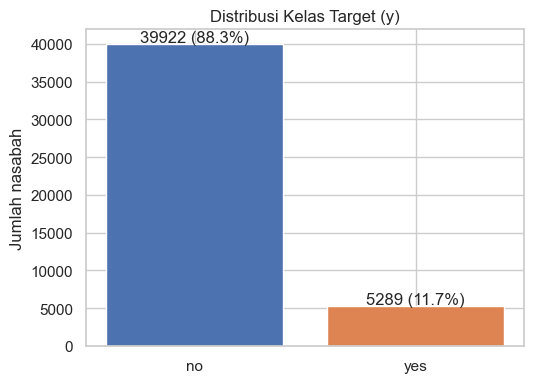

y
no     0.883
yes    0.117
Name: proportion, dtype: float64


In [24]:
# Salwa Azzahra Rambe_202431079
os.makedirs('fig', exist_ok=True)

# Distribusi target (y)
fig, ax = plt.subplots(figsize=(5.5, 4))
hitung = df['y'].value_counts()
ax.bar(hitung.index, hitung.values, color=['#4C72B0', '#DD8452'])
for i, v in enumerate(hitung.values):
    ax.text(i, v + 300, f'{v} ({v/len(df)*100:.1f}%)', ha='center')
ax.set_title('Distribusi Kelas Target (y)')
ax.set_ylabel('Jumlah nasabah')

plt.tight_layout()
plt.savefig('fig/01_target.png', dpi=150)
plt.show()
print(df['y'].value_counts(normalize=True).round(4))

# Distribusi Variabel Numerik

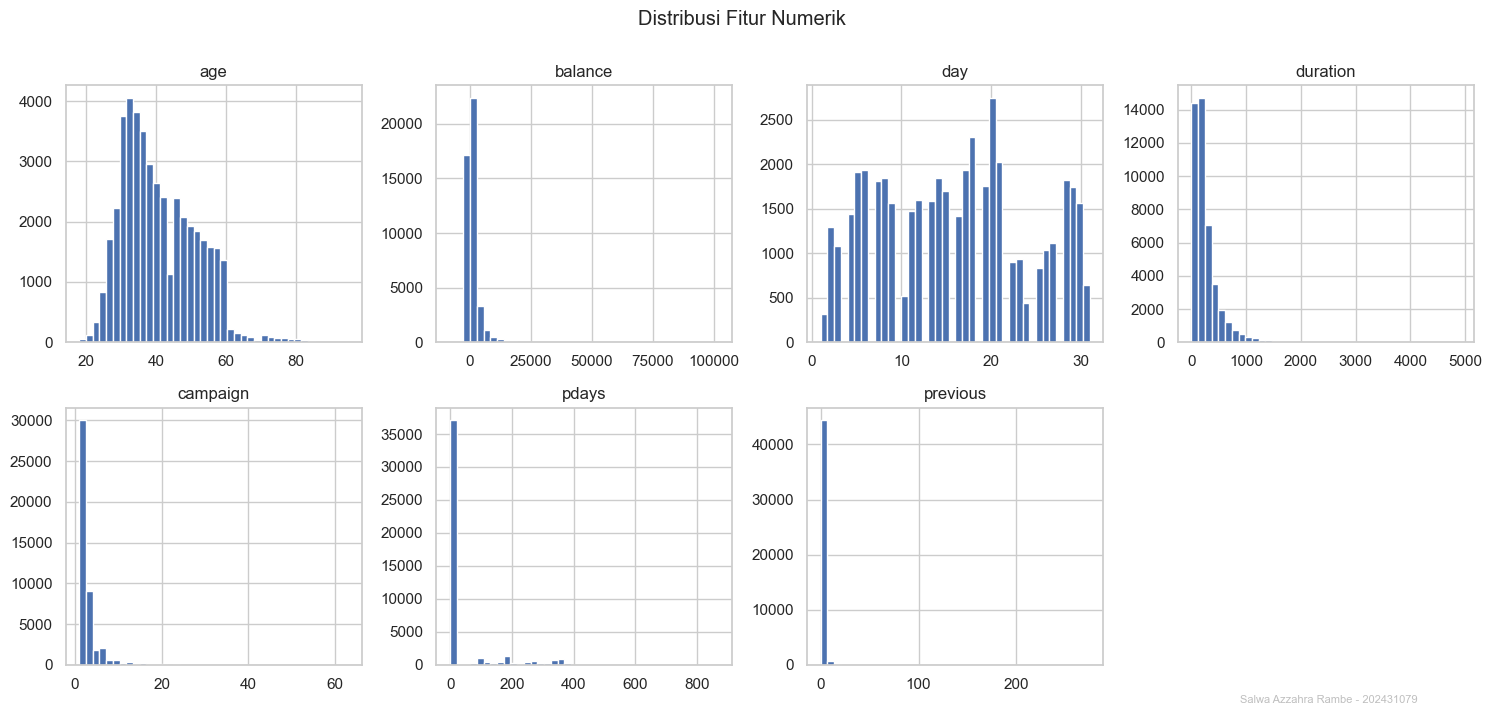

Skewness:
age          0.68
balance      8.36
day          0.09
duration     3.14
campaign     4.90
pdays        2.62
previous    41.85
dtype: float64


In [25]:
# Salwa Azzahra Rambe_202431079
# Histogram semua kolom numerik
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), fitur_num):
    ax.hist(df[c], bins=40, color='#4C72B0')
    ax.set_title(c)
axes.ravel()[-1].axis('off')
fig.suptitle('Distribusi Fitur Numerik', y=1.0)
watermark(fig)
plt.tight_layout()
plt.savefig('fig/02_hist.png', dpi=130)
plt.show()

# Skewness (kemiringan) tiap kolom
print('Skewness:')
print(df[fitur_num].skew().round(2))

# Identificatioin of Atypical Data

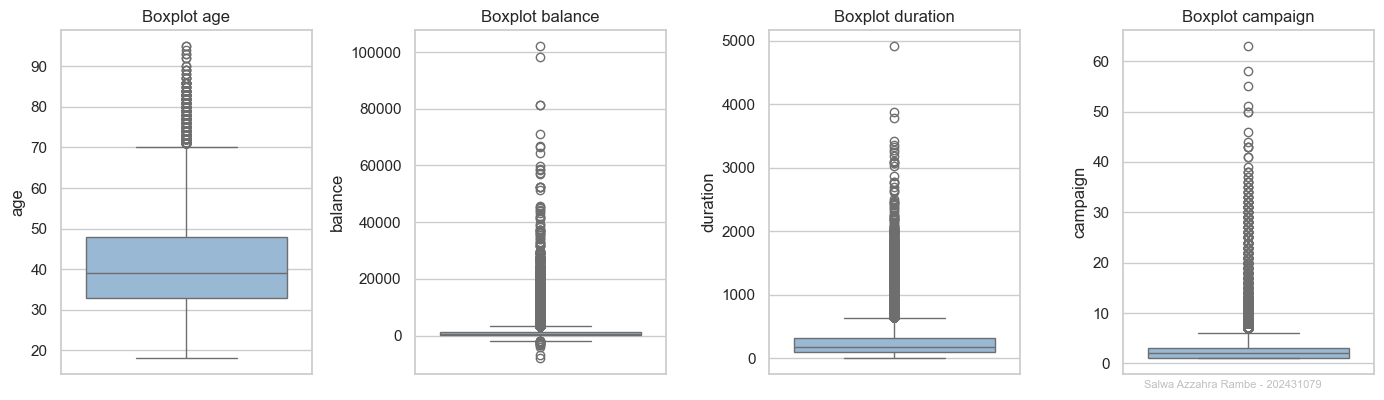

,jumlah_outlier_IQR
age,487
balance,4729
day,0
duration,3235
campaign,3064
pdays,8257
previous,8257


In [26]:
# Salwa Azzahra Rambe_202431079
# Boxplot beberapa kolom numerik
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axes, ['age', 'balance', 'duration', 'campaign']):
    sns.boxplot(y=df[c], ax=ax, color='#8FB8DE')
    ax.set_title('Boxplot ' + c)
watermark(fig)
plt.tight_layout()
plt.savefig('fig/03_box.png', dpi=140)
plt.show()

# Deteksi outlier dengan IQR
jumlah_outlier = {}
for c in fitur_num:
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    IQR = Q3 - Q1
    jumlah_outlier[c] = ((df[c] < Q1 - 1.5 * IQR) | (df[c] > Q3 + 1.5 * IQR)).sum()

pd.DataFrame({'jumlah_outlier_IQR': jumlah_outlier})

# Correlation of Variables 

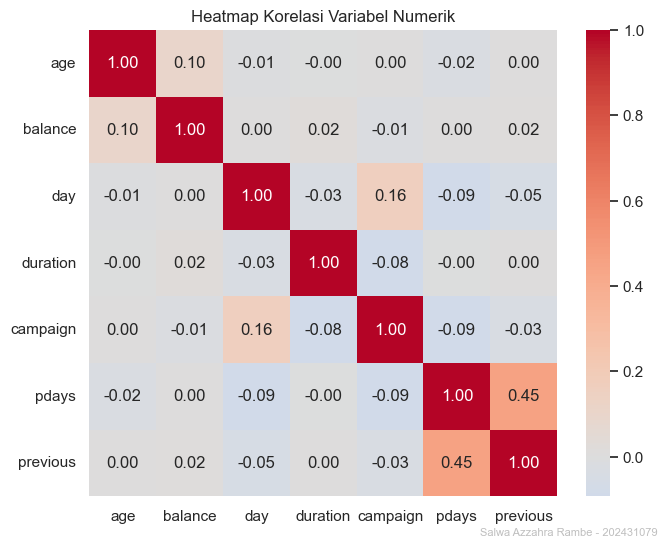

In [27]:
# Salwa Azzahra Rambe_202431079
# Heatmap korelasi hanya untuk variabel numerik
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[fitur_num].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Heatmap Korelasi Variabel Numerik')
watermark(fig)
plt.tight_layout()
plt.savefig('fig/04_corr.png', dpi=140)
plt.show()

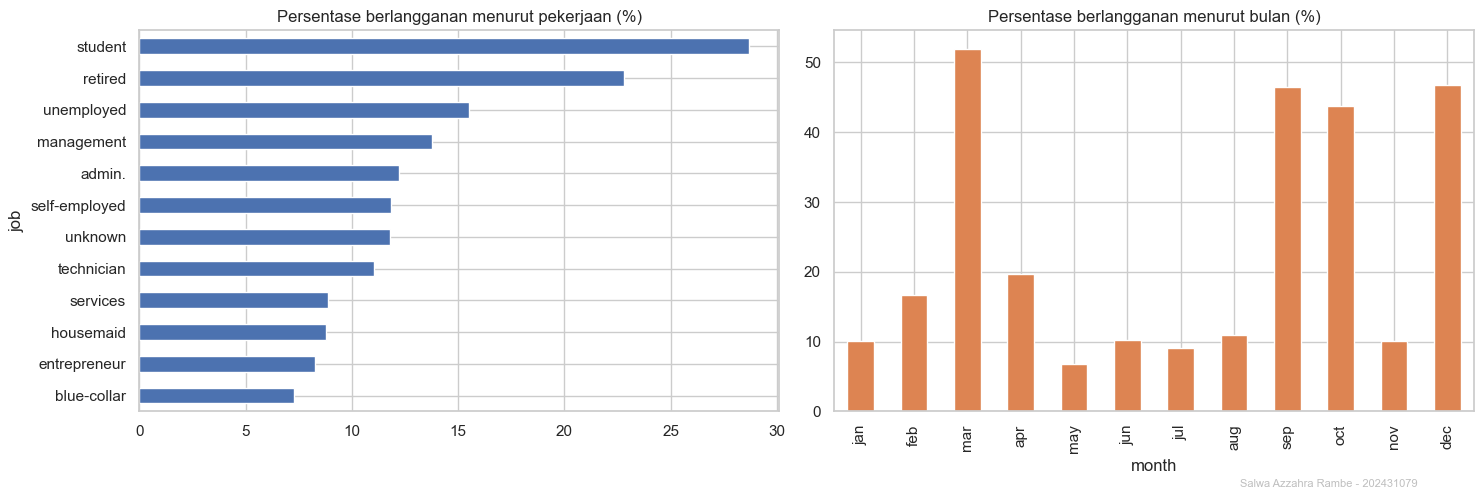

In [29]:
# Salwa Azzahra Rambe_202431079
# Hubungan variabel dengan target: persentase berlangganan menurut pekerjaan dan bulan
df['y_num'] = (df['y'] == 'yes').astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
(df.groupby('job')['y_num'].mean().sort_values() * 100).plot.barh(ax=axes[0], color='#4C72B0')
axes[0].set_title('Persentase berlangganan menurut pekerjaan (%)')

urut = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
(df.groupby('month')['y_num'].mean().reindex(urut) * 100).plot.bar(ax=axes[1], color='#DD8452')
axes[1].set_title('Persentase berlangganan menurut bulan (%)')
watermark(fig)
plt.tight_layout()
plt.savefig('fig/05_rate.png', dpi=140)
plt.show()

df = df.drop(columns='y_num')

# Pembagian Data

In [31]:
# Salwa Azzahra Rambe_202431079
from sklearn.model_selection import train_test_split

# nilai 'unknown' dipertahankan sebagai kategori tersendiri
X = df[fitur_num + fitur_kat]
y = (df['y'] == 'yes').astype(int)      # no = 0, yes = 1

# Split data latih 80% dan data uji 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Data latih :', X_train.shape, '| Data uji:', X_test.shape)
print('Proporsi yes (latih):', round(y_train.mean(), 4), '| (uji):', round(y_test.mean(), 4))

Data latih : (36168, 16) | Data uji: (9043, 16)
Proporsi yes (latih): 0.117 | (uji): 0.117


# Naive Bayes

In [32]:
# Salwa Azzahra Rambe_202431079
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Fungsi kecil untuk merangkum metrik klasifikasi (kelas yes)
def evaluasi(nama, y_asli, y_pred):
    return {'Model': nama,
            'Accuracy': accuracy_score(y_asli, y_pred),
            'Precision(yes)': precision_score(y_asli, y_pred),
            'Recall(yes)': recall_score(y_asli, y_pred),
            'F1(yes)': f1_score(y_asli, y_pred)}

# Model A: Gaussian Naive Bayes
# 1) kolom kategorikal diubah menjadi kolom 0/1 (one-hot)
X_a = pd.concat([X[fitur_num], pd.get_dummies(X[fitur_kat]).astype(float)], axis=1)
X_train_a = X_a.loc[X_train.index].copy()
X_test_a = X_a.loc[X_test.index].copy()

# 2) kolom numerik distandardisasi (fit hanya pada data latih)
scaler = StandardScaler()
X_train_a[fitur_num] = scaler.fit_transform(X_train_a[fitur_num])
X_test_a[fitur_num] = scaler.transform(X_test_a[fitur_num])

# 3) latih model dan prediksi data uji
nb_a = GaussianNB()
nb_a.fit(X_train_a, y_train)
pred_a = nb_a.predict(X_test_a)

print('Jumlah fitur setelah encoding:', X_train_a.shape[1])
print(classification_report(y_test, pred_a, target_names=['no', 'yes'], digits=4))

Jumlah fitur setelah encoding: 51
              precision    recall  f1-score   support

          no     0.9339    0.8992    0.9162      7985
         yes     0.4059    0.5198    0.4559      1058

    accuracy                         0.8548      9043
   macro avg     0.6699    0.7095    0.6860      9043
weighted avg     0.8721    0.8548    0.8624      9043



In [33]:
# Salwa Azzahra Rambe_202431079
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

# Model B: Categorical Naive Bayes
# 1) kolom numerik dibagi menjadi 5 interval (bin) berdasarkan kuantil
diskret = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
num_train = diskret.fit_transform(X_train[fitur_num])
num_test = diskret.transform(X_test[fitur_num])

# 2) kolom kategorikal diberi kode angka
kode = OrdinalEncoder()
kat_train = kode.fit_transform(X_train[fitur_kat])
kat_test = kode.transform(X_test[fitur_kat])

# 3) gabungkan kolom numerik dan kategorikal
X_train_b = np.hstack([num_train, kat_train]).astype(int)
X_test_b = np.hstack([num_test, kat_test]).astype(int)
jumlah_kategori = np.maximum(X_train_b.max(axis=0), X_test_b.max(axis=0)) + 1

# 4) latih model (alpha=1 berarti Laplace smoothing) dan prediksi data uji
nb_b = CategoricalNB(alpha=1.0, min_categories=jumlah_kategori)
nb_b.fit(X_train_b, y_train)
pred_b = nb_b.predict(X_test_b)

print(classification_report(y_test, pred_b, target_names=['no', 'yes'], digits=4))

              precision    recall  f1-score   support

          no     0.9250    0.9564    0.9405      7985
         yes     0.5578    0.4149    0.4759      1058

    accuracy                         0.8931      9043
   macro avg     0.7414    0.6857    0.7082      9043
weighted avg     0.8821    0.8931    0.8861      9043



In [34]:
# Salwa Azzahra Rambe_202431079
# Perbandingan kedua model dan baseline (selalu menebak no)
hasil_nb = pd.DataFrame([
    evaluasi('Gaussian NB (Model A)', y_test, pred_a),
    evaluasi('Categorical NB (Model B)', y_test, pred_b),
    {'Model': 'Baseline (selalu tebak no)', 'Accuracy': (y_test == 0).mean(),
     'Precision(yes)': 0.0, 'Recall(yes)': 0.0, 'F1(yes)': 0.0}]).round(4)
hasil_nb

,Model,Accuracy,Precision(yes),Recall(yes),F1(yes)
0,Gaussian NB (Model A),0.8548,0.4059,0.5198,0.4559
1,Categorical NB (Model B),0.8931,0.5578,0.4149,0.4759
2,Baseline (selalu tebak no),0.8830,0.0000,0.0000,0.0000


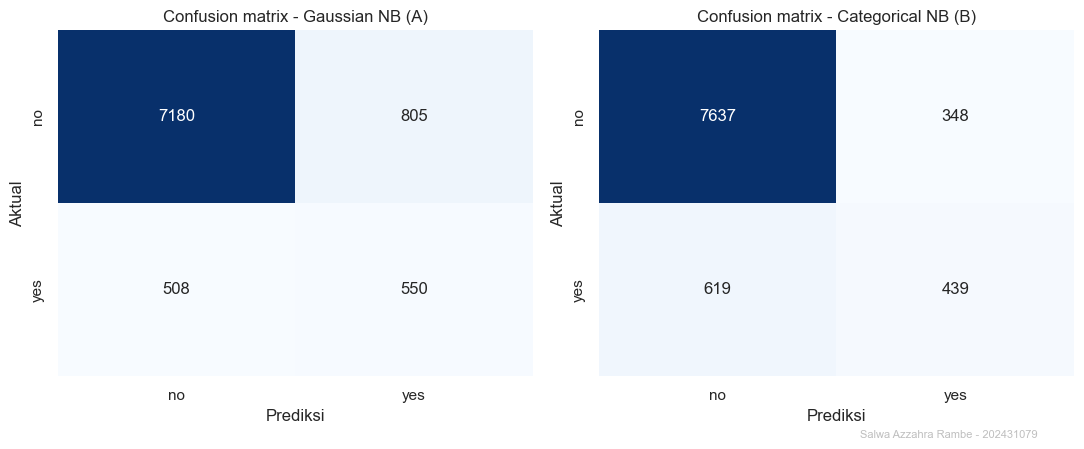

In [35]:
# Salwa Azzahra Rambe_202431079
# Confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nama, pr) in zip(axes, [('Gaussian NB (A)', pred_a), ('Categorical NB (B)', pred_b)]):
    cm = confusion_matrix(y_test, pr)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
    ax.set_title('Confusion matrix - ' + nama)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
watermark(fig)
plt.tight_layout()
plt.savefig('fig/06_cm.png', dpi=140)
plt.show()

In [36]:
# Salwa Azzahra Rambe_202431079
from imblearn.over_sampling import SMOTE

# SMOTE hanya dipakai pada data latih Model A
smote = SMOTE(random_state=42)
X_train_s, y_train_s = smote.fit_resample(X_train_a, y_train)
print('Distribusi latih sebelum SMOTE:', dict(y_train.value_counts()))
print('Distribusi latih sesudah SMOTE:', dict(pd.Series(y_train_s).value_counts()))

nb_s = GaussianNB()
nb_s.fit(X_train_s, y_train_s)
pred_s = nb_s.predict(X_test_a)

hasil_nb2 = pd.DataFrame([
    evaluasi('Gaussian NB (tanpa SMOTE)', y_test, pred_a),
    evaluasi('Gaussian NB (+ SMOTE)', y_test, pred_s),
    evaluasi('Categorical NB (tanpa SMOTE)', y_test, pred_b)]).round(4)
hasil_nb2

Distribusi latih sebelum SMOTE: {0: np.int64(31937), 1: np.int64(4231)}
Distribusi latih sesudah SMOTE: {0: np.int64(31937), 1: np.int64(31937)}


,Model,Accuracy,Precision(yes),Recall(yes),F1(yes)
0,Gaussian NB (tanpa SMOTE),0.8548,0.4059,0.5198,0.4559
1,Gaussian NB (+ SMOTE),0.7892,0.3117,0.6635,0.4242
2,Categorical NB (tanpa SMOTE),0.8931,0.5578,0.4149,0.4759


In [37]:
# Salwa Azzahra Rambe_202431079
# Categorical NB tanpa fitur duration
fitur_num2 = [c for c in fitur_num if c != 'duration']

diskret2 = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
num_train2 = diskret2.fit_transform(X_train[fitur_num2])
num_test2 = diskret2.transform(X_test[fitur_num2])

X_train_c = np.hstack([num_train2, kat_train]).astype(int)
X_test_c = np.hstack([num_test2, kat_test]).astype(int)
jumlah_kategori2 = np.maximum(X_train_c.max(axis=0), X_test_c.max(axis=0)) + 1

nb_c = CategoricalNB(alpha=1.0, min_categories=jumlah_kategori2)
nb_c.fit(X_train_c, y_train)
pred_c = nb_c.predict(X_test_c)

pd.DataFrame([evaluasi('Categorical NB (dengan duration)', y_test, pred_b),
              evaluasi('Categorical NB (tanpa duration)', y_test, pred_c)]).round(4)

,Model,Accuracy,Precision(yes),Recall(yes),F1(yes)
0,Categorical NB (dengan duration),0.8931,0.5578,0.4149,0.4759
1,Categorical NB (tanpa duration),0.8844,0.5097,0.3214,0.3942


In [38]:
# Salwa Azzahra Rambe_202431079
# Contoh hasil prediksi Model B pada 10 data uji
contoh = X_test.copy()
contoh['aktual'] = y_test.map({0: 'no', 1: 'yes'})
contoh['prediksi'] = pd.Series(pred_b, index=X_test.index).map({0: 'no', 1: 'yes'})
contoh['peluang_yes'] = nb_b.predict_proba(X_test_b)[:, 1].round(3)
contoh[['age', 'job', 'balance', 'duration', 'aktual', 'prediksi', 'peluang_yes']].head(10)

,age,job,balance,duration,aktual,prediksi,peluang_yes
1392,40,blue-collar,640,347,no,no,0.002
7518,44,technician,378,203,no,no,0.004
12007,31,services,356,228,no,no,0.005
5536,36,blue-collar,655,153,no,no,0.001
29816,34,services,1921,61,no,no,0.012
18275,41,management,1138,283,no,no,0.138
8543,43,entrepreneur,2589,38,no,no,0.002
43965,64,retired,109,706,yes,yes,0.960
28083,35,admin.,1803,61,no,no,0.009
25787,44,services,2279,105,no,no,0.045


# Regresi Linear

In [39]:
# Salwa Azzahra Rambe_202431079
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target regresi: balance (saldo rata-rata tahunan)
fitur_r_num = ['age', 'day', 'duration', 'campaign', 'pdays', 'previous']

# Kolom kategorikal diubah menjadi dummy (drop_first=True agar tidak terjadi dummy trap)
x = pd.get_dummies(df[fitur_r_num + fitur_kat], columns=fitur_kat, drop_first=True).astype(float)
y_reg = df['balance']

# Split data latih dan data uji
x_train, x_test, y_train_r, y_test_r = train_test_split(x, y_reg, test_size=0.2, random_state=42)

print('Jumlah fitur regresi:', x.shape[1])
print('Data latih:', x_train.shape, '| Data uji:', x_test.shape)
print(y_reg.describe().round(2))

Jumlah fitur regresi: 41
Data latih: (36168, 41) | Data uji: (9043, 41)
count     45211.00
mean       1362.27
std        3044.77
min       -8019.00
25%          72.00
50%         448.00
75%        1428.00
max      102127.00
Name: balance, dtype: float64


In [40]:
# Salwa Azzahra Rambe_202431079
# Buat model regresi linear dan latih
model = LinearRegression()
model.fit(x_train, y_train_r)

# Prediksi data latih dan data uji
pred_tr = model.predict(x_train)
pred_te = model.predict(x_test)

# Evaluasi model
def metrik(y_asli, y_pred):
    mse = mean_squared_error(y_asli, y_pred)
    return {'MAE': mean_absolute_error(y_asli, y_pred), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(y_asli, y_pred)}

hasil_lr = pd.DataFrame({'Latih': metrik(y_train_r, pred_tr), 'Uji': metrik(y_test_r, pred_te)}).T.round(4)
print('Intercept:', round(model.intercept_, 2))
hasil_lr

Intercept: -33.08


,MAE,MSE,RMSE,R2
Latih,1475.6535,8.673723e+06,2945.1186,0.0509
Uji,1486.8629,9.338627e+06,3055.9168,0.0468


In [41]:
# Salwa Azzahra Rambe_202431079
# Koefisien regresi, diurutkan dari pengaruh terbesar
koef = pd.Series(model.coef_, index=x.columns)
tabel_koef = pd.DataFrame({'koefisien': koef.round(2), 'abs': koef.abs()})
tabel_koef = tabel_koef.sort_values('abs', ascending=False).drop(columns='abs')
tabel_koef.head(12)

,koefisien
default_yes,-1286.92
month_nov,798.19
month_jan,-783.90
month_jul,-589.70
loan_yes,-539.43
education_tertiary,464.10
month_oct,420.43
marital_single,399.14
month_aug,-365.90
month_feb,-329.37


In [42]:
# Salwa Azzahra Rambe_202431079
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Cek multikolinearitas dengan VIF
xc = sm.add_constant(x_train)
vif = pd.Series([variance_inflation_factor(xc.values, i) for i in range(1, xc.shape[1])],
                index=x_train.columns).sort_values(ascending=False).round(2)
print('VIF tertinggi:')
vif.head(8)

VIF tertinggi:


poutcome_unknown      6.19
month_may             4.77
pdays                 4.65
month_jun             3.55
education_tertiary    3.39
month_aug             3.11
month_jul             3.09
job_management        3.03
dtype: float64

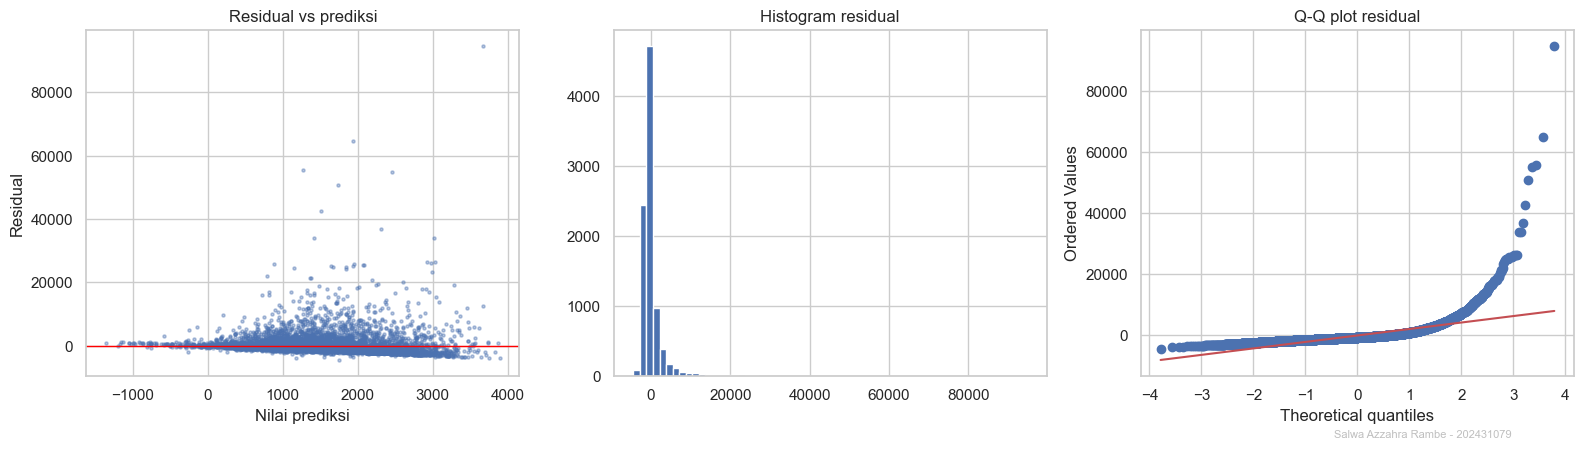

Skewness residual: 9.4
Rata-rata residual: -7.56


In [43]:
# Salwa Azzahra Rambe_202431079
from scipy import stats

# Cek residual (selisih aktual dan prediksi)
resid = y_test_r - pred_te
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(pred_te, resid, s=5, alpha=0.4, color='#4C72B0')
axes[0].axhline(0, color='red', lw=1)
axes[0].set_xlabel('Nilai prediksi')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residual vs prediksi')
axes[1].hist(resid, bins=60, color='#4C72B0')
axes[1].set_title('Histogram residual')
stats.probplot(resid, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q plot residual')
watermark(fig)
plt.tight_layout()
plt.savefig('fig/07_resid.png', dpi=140)
plt.show()
print('Skewness residual:', round(stats.skew(resid), 2))
print('Rata-rata residual:', round(resid.mean(), 2))

In [44]:
# Salwa Azzahra Rambe_202431079
# Perbaikan: batasi balance pada persentil 1 dan 99 (winsorize)
b_bawah, b_atas = y_train_r.quantile([0.01, 0.99])
y_train_w = y_train_r.clip(b_bawah, b_atas)
y_test_w = y_test_r.clip(b_bawah, b_atas)

model_w = LinearRegression()
model_w.fit(x_train, y_train_w)
pred_w = model_w.predict(x_test)

banding = pd.DataFrame({'Model awal (balance asli)': metrik(y_test_r, pred_te),
                        'Model winsorize (1-99%)': metrik(y_test_w, pred_w)}).T.round(4)
print('Batas winsorize:', round(b_bawah, 1), 'sampai', round(b_atas, 1))
banding

Batas winsorize: -636.0 sampai 13107.0


,MAE,MSE,RMSE,R2
Model awal (balance asli),1486.8629,9.338627e+06,3055.9168,0.0468
Model winsorize (1-99%),1348.8522,4.714588e+06,2171.3102,0.0643


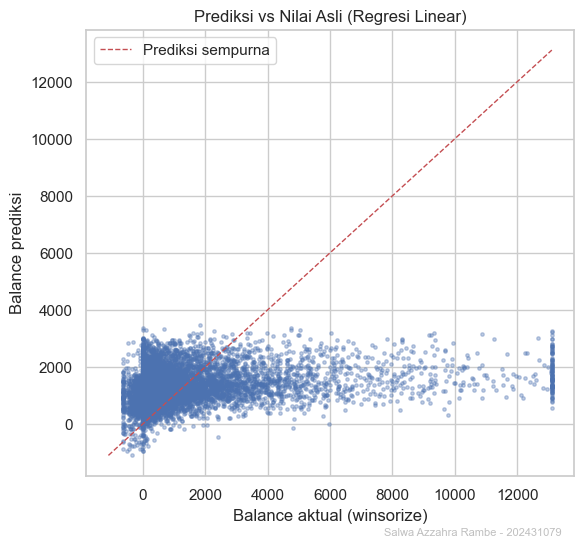

,balance_aktual,balance_prediksi,selisih
0,580,981.0,-401.0
1,3644,1567.0,2077.0
2,538,1610.0,-1072.0
3,1773,1874.0,-101.0
4,217,1299.0,-1082.0
5,1134,870.0,264.0
6,1085,768.0,317.0
7,127,1667.0,-1540.0
8,3,672.0,-669.0
9,258,1218.0,-960.0


In [45]:
# Salwa Azzahra Rambe_202431079
# Visualisasi prediksi vs nilai asli
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(y_test_w, pred_w, s=6, alpha=0.35, color='#4C72B0')
batas = [min(y_test_w.min(), pred_w.min()), max(y_test_w.max(), pred_w.max())]
ax.plot(batas, batas, 'r--', lw=1, label='Prediksi sempurna')
ax.set_xlabel('Balance aktual (winsorize)')
ax.set_ylabel('Balance prediksi')
ax.set_title('Prediksi vs Nilai Asli (Regresi Linear)')
ax.legend()
watermark(fig)
plt.tight_layout()
plt.savefig('fig/08_actual_pred.png', dpi=140)
plt.show()

# Contoh 10 hasil prediksi
contoh_r = pd.DataFrame({'balance_aktual': y_test_w.values[:10].round(0),
                         'balance_prediksi': pred_w[:10].round(0)})
contoh_r['selisih'] = (contoh_r['balance_aktual'] - contoh_r['balance_prediksi']).round(0)
contoh_r